# One-Page Visual Report for the Duka Electronics Board

This project creates a one-page visual report for the Duka Electronics board using H1 2026 sales data. The report focuses on branch performance, monthly revenue trends, product performance and where management should focus in the second half of the year.

## Storyboard

### Audience

The audience is the Duka Electronics board and CEO. They need a quick, clear view of H1 2026 sales performance before deciding where to focus management attention and marketing resources in H2.

### Decision

The board needs to decide which branches and areas of the business should receive the most attention in the second half of 2026.

### Big Idea

Nairobi remains the strongest revenue branch, but H2 attention should focus on recovering Mombasa and Nakuru, where Q2 revenue fell sharply, while protecting growth in Eldoret and Kisumu.

### Situation

Duka Electronics generated strong H1 revenue, led by Nairobi, which remained the largest branch by total revenue.

### Complication

Performance was uneven across branches: Eldoret and Kisumu improved in Q2, while Mombasa and Nakuru declined by about a quarter compared with Q1.

### Resolution

The board should prioritise recovery actions in Mombasa and Nakuru, while maintaining support for the branches showing positive momentum.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sales = pd.read_csv(
    "duka_sales.csv",
    parse_dates=["order_date"]
)

sales["revenue"] = sales["quantity"] * sales["unit_price"]

print("Rows:", len(sales))
print("Total revenue:", sales["revenue"].sum())
print("Date range:", sales["order_date"].min(), "to", sales["order_date"].max())

Rows: 1000
Total revenue: 71792500
Date range: 2026-01-01 00:00:00 to 2026-06-29 00:00:00


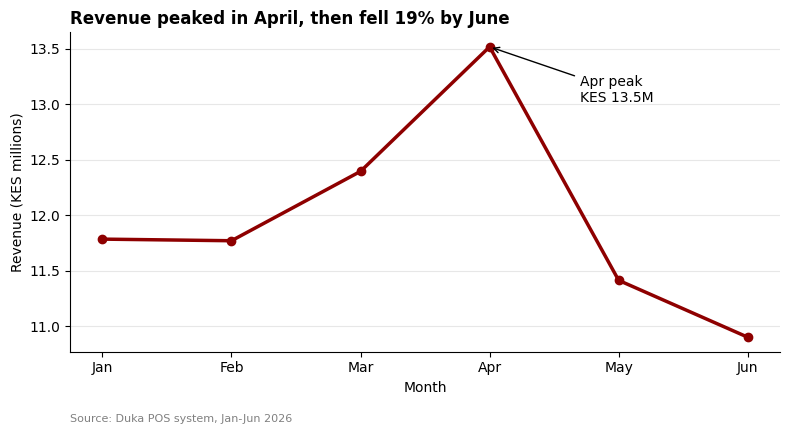

In [2]:
monthly = (
    sales.set_index("order_date")
    .resample("MS")["revenue"]
    .sum()
)

labels = monthly.index.strftime("%b")

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    labels,
    monthly.values / 1e6,
    marker="o",
    linewidth=2.5,
    color="#8E0000"
)

peak_idx = monthly.values.argmax()

ax.annotate(
    f"{labels[peak_idx]} peak\nKES {monthly.max()/1e6:.1f}M",
    xy=(peak_idx, monthly.max()/1e6),
    xytext=(peak_idx + 0.7, monthly.max()/1e6 - 0.5),
    arrowprops=dict(arrowstyle="->")
)

drop = (
    monthly.iloc[-1] / monthly.max() - 1
) * 100

ax.set_title(
    f"Revenue peaked in {monthly.idxmax():%B}, then fell {abs(drop):.0f}% by June",
    loc="left",
    fontweight="bold"
)

ax.set_ylabel("Revenue (KES millions)")
ax.set_xlabel("Month")

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)

ax.text(
    0,
    -0.22,
    "Source: Duka POS system, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=8,
    color="grey"
)

plt.tight_layout()
plt.show()

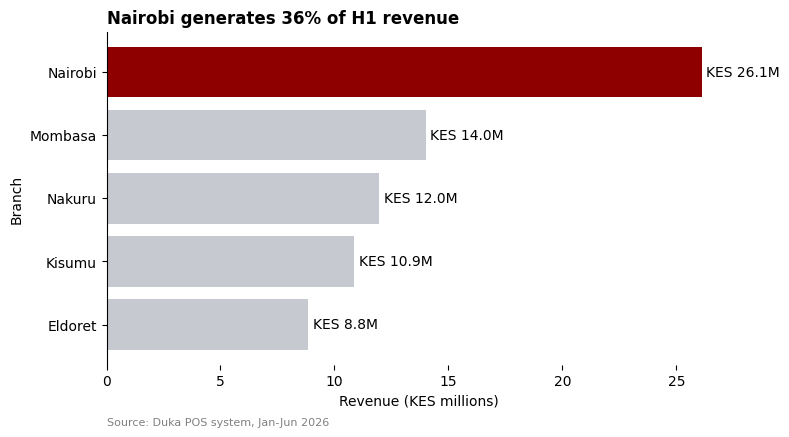

In [3]:
branch_rev = (
    sales.groupby("branch")["revenue"]
    .sum()
    .sort_values()
)

top_branch = branch_rev.idxmax()

colors = [
    "#8E0000" if branch == top_branch else "#C7C9D1"
    for branch in branch_rev.index
]

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.barh(
    branch_rev.index,
    branch_rev.values / 1e6,
    color=colors
)

for bar, value in zip(bars, branch_rev.values):
    ax.text(
        value / 1e6 + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"KES {value/1e6:.1f}M",
        va="center"
    )

share = branch_rev.max() / branch_rev.sum()

ax.set_title(
    f"{top_branch} generates {share:.0%} of H1 revenue",
    loc="left",
    fontweight="bold"
)

ax.set_xlabel("Revenue (KES millions)")
ax.set_ylabel("Branch")

ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.grid(False)

ax.text(
    0,
    -0.18,
    "Source: Duka POS system, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=8,
    color="grey"
)

plt.tight_layout()
plt.show()

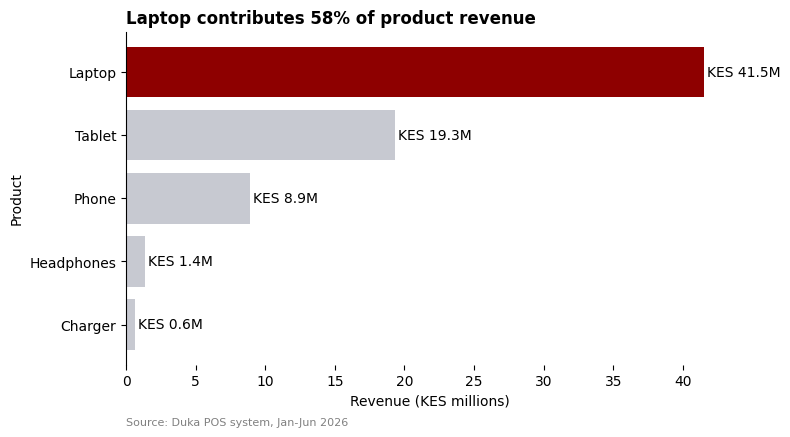

In [4]:
product_rev = (
    sales.groupby("product")["revenue"]
    .sum()
    .sort_values()
)

top_product = product_rev.idxmax()

colors = [
    "#8E0000" if product == top_product else "#C7C9D1"
    for product in product_rev.index
]

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.barh(
    product_rev.index,
    product_rev.values / 1e6,
    color=colors
)

for bar, value in zip(bars, product_rev.values):
    ax.text(
        value / 1e6 + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"KES {value/1e6:.1f}M",
        va="center"
    )

share = product_rev.max() / product_rev.sum()

ax.set_title(
    f"{top_product} contributes {share:.0%} of product revenue",
    loc="left",
    fontweight="bold"
)

ax.set_xlabel("Revenue (KES millions)")
ax.set_ylabel("Product")

ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.grid(False)

ax.text(
    0,
    -0.18,
    "Source: Duka POS system, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=8,
    color="grey"
)

plt.tight_layout()
plt.show()

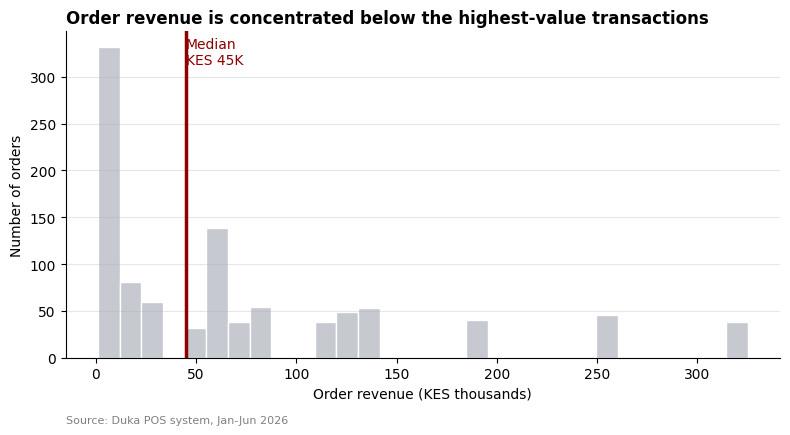

In [5]:
order_revenue = sales["revenue"] / 1000

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.hist(
    order_revenue,
    bins=30,
    color="#C7C9D1",
    edgecolor="white"
)

median_value = order_revenue.median()

ax.axvline(
    median_value,
    color="#8E0000",
    linewidth=2.5
)

ax.text(
    median_value,
    ax.get_ylim()[1] * 0.9,
    f"Median\nKES {median_value:,.0f}K",
    color="#8E0000",
    ha="left"
)

ax.set_title(
    "Order revenue is concentrated below the highest-value transactions",
    loc="left",
    fontweight="bold"
)

ax.set_xlabel("Order revenue (KES thousands)")
ax.set_ylabel("Number of orders")

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)

ax.text(
    0,
    -0.20,
    "Source: Duka POS system, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=8,
    color="grey"
)

plt.tight_layout()
plt.show()

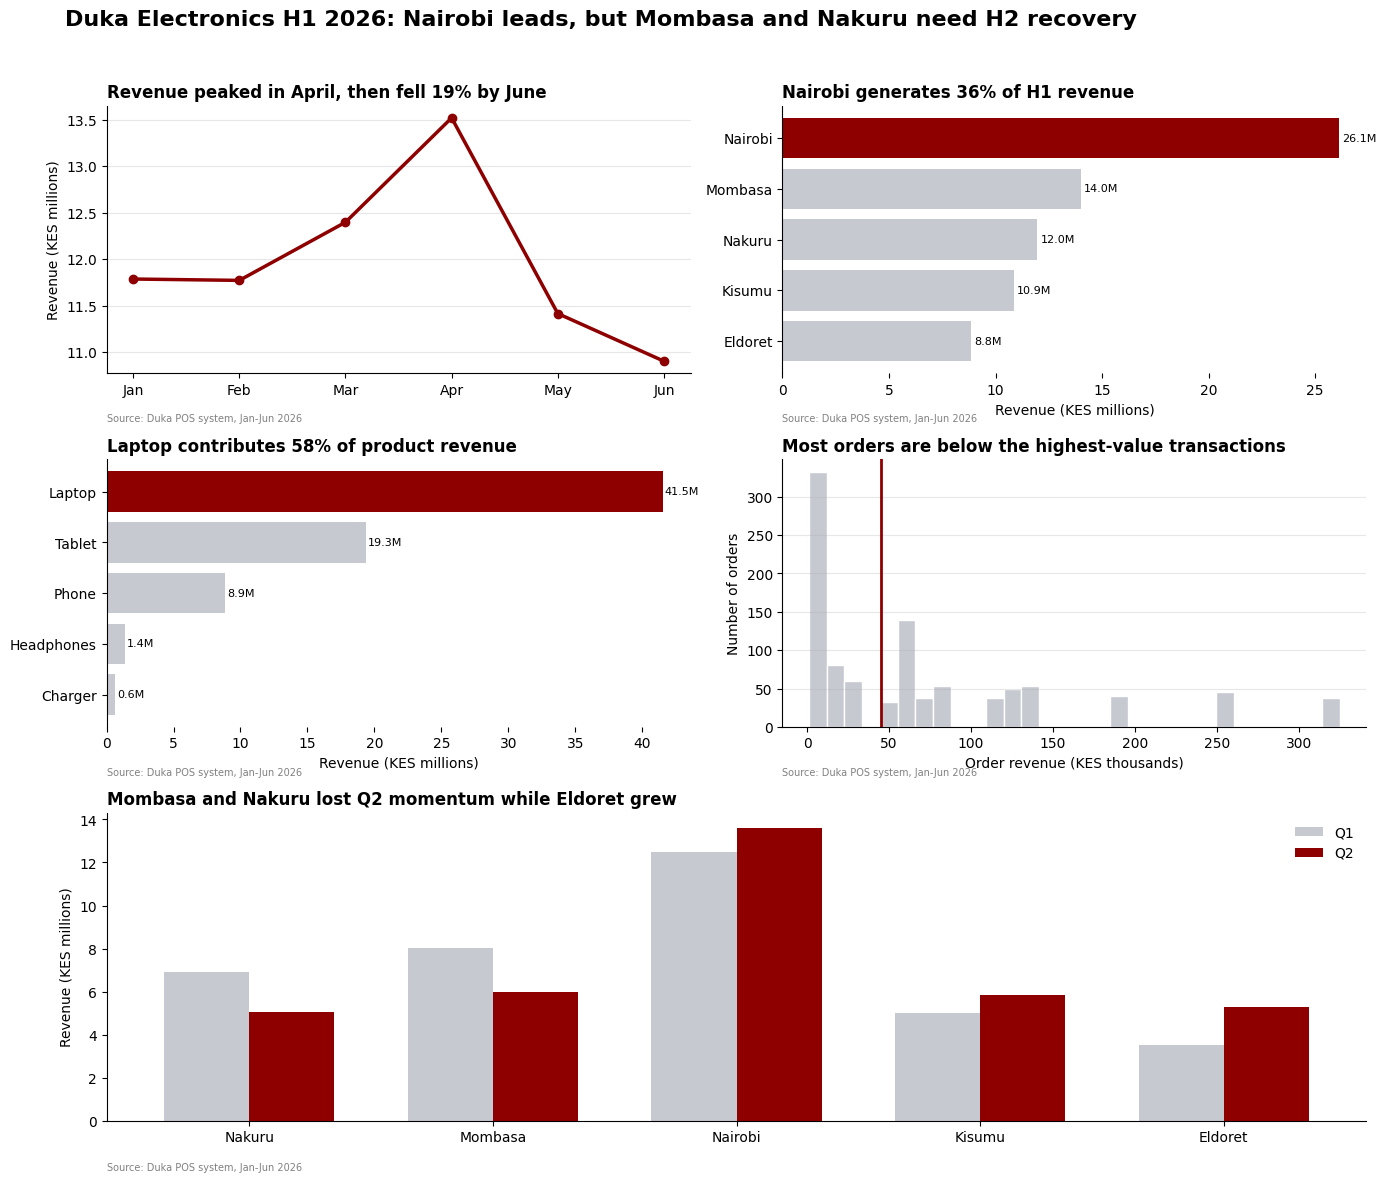

In [6]:
import os

os.makedirs("reports", exist_ok=True)

# Prepare summaries
monthly = (
    sales.set_index("order_date")
    .resample("MS")["revenue"]
    .sum()
)

branch_rev = (
    sales.groupby("branch")["revenue"]
    .sum()
    .sort_values()
)

product_rev = (
    sales.groupby("product")["revenue"]
    .sum()
    .sort_values()
)

order_revenue = sales["revenue"] / 1000

sales["quarter"] = np.where(
    sales["order_date"].dt.month <= 3,
    "Q1",
    "Q2"
)

quarter_branch = pd.pivot_table(
    sales,
    index="branch",
    columns="quarter",
    values="revenue",
    aggfunc="sum"
)

quarter_branch["change_pct"] = (
    (quarter_branch["Q2"] / quarter_branch["Q1"] - 1) * 100
)

quarter_branch = quarter_branch.sort_values("change_pct")

# Create one-page report
fig = plt.figure(figsize=(14, 12))

gs = fig.add_gridspec(
    3,
    2,
    height_ratios=[1, 1, 1.15]
)

fig.suptitle(
    "Duka Electronics H1 2026: Nairobi leads, but Mombasa and Nakuru need H2 recovery",
    fontsize=16,
    fontweight="bold",
    x=0.05,
    ha="left"
)

# 1. Monthly revenue trend
ax = fig.add_subplot(gs[0, 0])

labels = monthly.index.strftime("%b")

ax.plot(
    labels,
    monthly.values / 1e6,
    marker="o",
    linewidth=2.5,
    color="#8E0000"
)

drop = (monthly.iloc[-1] / monthly.max() - 1) * 100

ax.set_title(
    f"Revenue peaked in April, then fell {abs(drop):.0f}% by June",
    loc="left",
    fontweight="bold"
)

ax.set_ylabel("Revenue (KES millions)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)

ax.text(
    0,
    -0.18,
    "Source: Duka POS system, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=7,
    color="grey"
)

# 2. Revenue by branch
ax = fig.add_subplot(gs[0, 1])

top_branch = branch_rev.idxmax()

colors = [
    "#8E0000" if branch == top_branch else "#C7C9D1"
    for branch in branch_rev.index
]

bars = ax.barh(
    branch_rev.index,
    branch_rev.values / 1e6,
    color=colors
)

for bar, value in zip(bars, branch_rev.values):
    ax.text(
        value / 1e6 + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{value/1e6:.1f}M",
        va="center",
        fontsize=8
    )

share = branch_rev.max() / branch_rev.sum()

ax.set_title(
    f"{top_branch} generates {share:.0%} of H1 revenue",
    loc="left",
    fontweight="bold"
)

ax.set_xlabel("Revenue (KES millions)")
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.grid(False)

ax.text(
    0,
    -0.18,
    "Source: Duka POS system, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=7,
    color="grey"
)

# 3. Revenue by product
ax = fig.add_subplot(gs[1, 0])

top_product = product_rev.idxmax()

colors = [
    "#8E0000" if product == top_product else "#C7C9D1"
    for product in product_rev.index
]

bars = ax.barh(
    product_rev.index,
    product_rev.values / 1e6,
    color=colors
)

for bar, value in zip(bars, product_rev.values):
    ax.text(
        value / 1e6 + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{value/1e6:.1f}M",
        va="center",
        fontsize=8
    )

share = product_rev.max() / product_rev.sum()

ax.set_title(
    f"{top_product} contributes {share:.0%} of product revenue",
    loc="left",
    fontweight="bold"
)

ax.set_xlabel("Revenue (KES millions)")
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.grid(False)

ax.text(
    0,
    -0.18,
    "Source: Duka POS system, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=7,
    color="grey"
)

# 4. Order revenue distribution
ax = fig.add_subplot(gs[1, 1])

ax.hist(
    order_revenue,
    bins=30,
    color="#C7C9D1",
    edgecolor="white"
)

median_value = order_revenue.median()

ax.axvline(
    median_value,
    color="#8E0000",
    linewidth=2
)

ax.set_title(
    "Most orders are below the highest-value transactions",
    loc="left",
    fontweight="bold"
)

ax.set_xlabel("Order revenue (KES thousands)")
ax.set_ylabel("Number of orders")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)

ax.text(
    0,
    -0.18,
    "Source: Duka POS system, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=7,
    color="grey"
)

# 5. Q1 vs Q2 branch performance
ax = fig.add_subplot(gs[2, :])

x = np.arange(len(quarter_branch))
width = 0.35

ax.bar(
    x - width / 2,
    quarter_branch["Q1"] / 1e6,
    width,
    label="Q1",
    color="#C7C9D1"
)

ax.bar(
    x + width / 2,
    quarter_branch["Q2"] / 1e6,
    width,
    label="Q2",
    color="#8E0000"
)

ax.set_xticks(x)
ax.set_xticklabels(quarter_branch.index)

ax.set_ylabel("Revenue (KES millions)")

ax.set_title(
    "Mombasa and Nakuru lost Q2 momentum while Eldoret grew",
    loc="left",
    fontweight="bold"
)

ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

ax.text(
    0,
    -0.16,
    "Source: Duka POS system, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=7,
    color="grey"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    "reports/duka_board_report.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### Before-and-After Design Changes

The original chart used a generic title, unsorted vertical bars and no direct value labels, making the main message harder to identify quickly.

The redesigned chart improves communication by:

- sorting the bars so products are easier to compare
- switching to horizontal bars for easier label reading
- highlighting only the top product
- using grey for the remaining products to reduce visual clutter
- adding direct revenue labels
- replacing the generic title with an insight title
- removing unnecessary chart borders
- adding a source and time-period line

These changes make the main finding easier for board members to understand quickly on a phone screen.

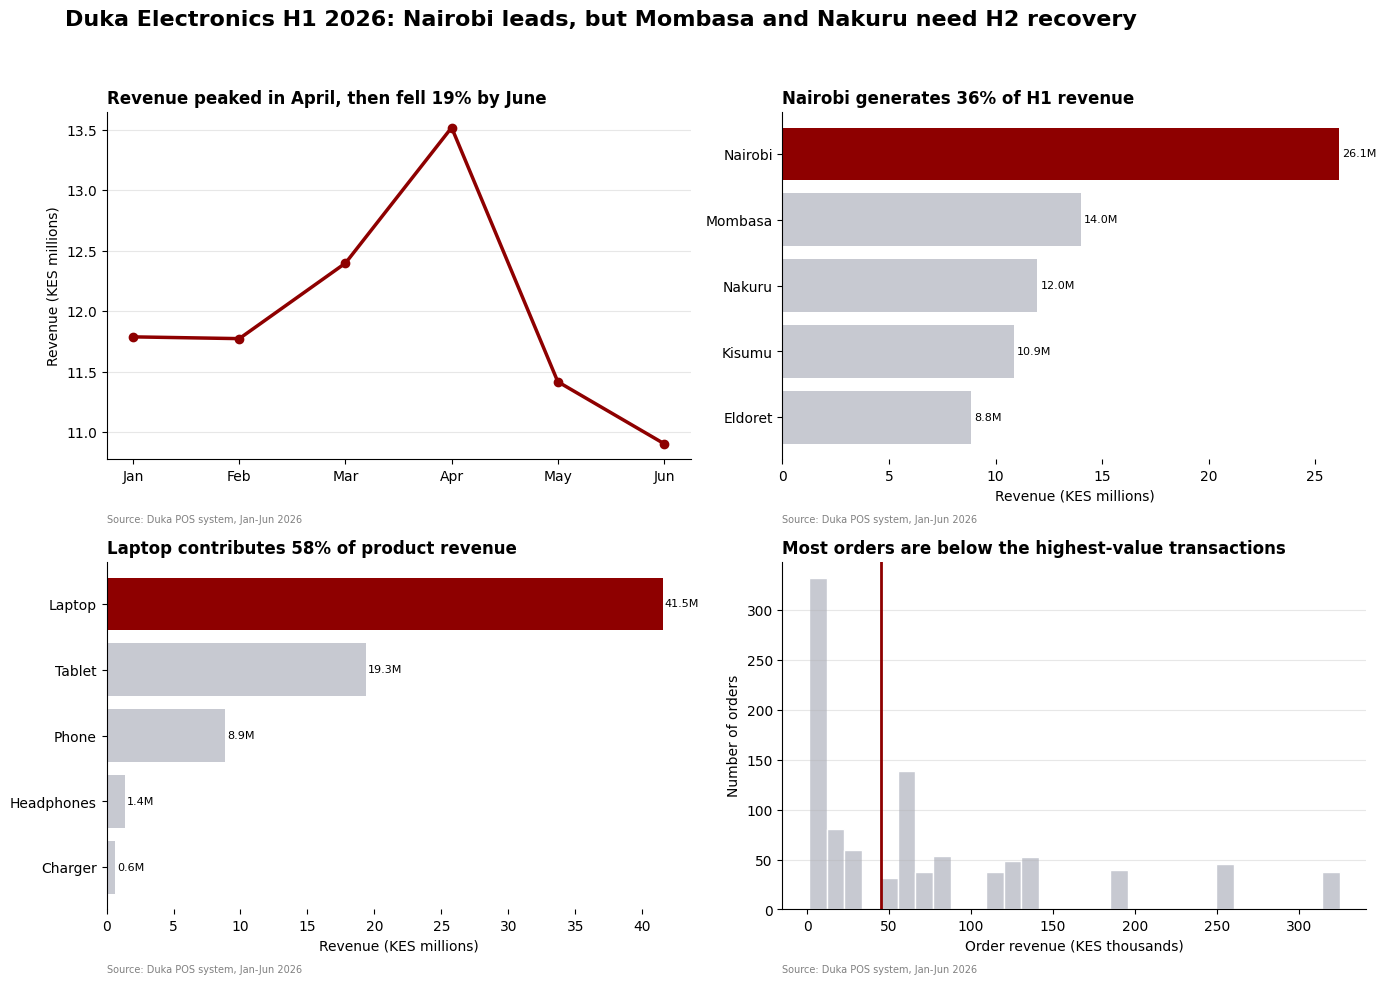

In [7]:
import os

os.makedirs("reports", exist_ok=True)

# Prepare summaries
monthly = (
    sales.set_index("order_date")
    .resample("MS")["revenue"]
    .sum()
)

branch_rev = (
    sales.groupby("branch")["revenue"]
    .sum()
    .sort_values()
)

product_rev = (
    sales.groupby("product")["revenue"]
    .sum()
    .sort_values()
)

order_revenue = sales["revenue"] / 1000

# Create report canvas
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

fig.suptitle(
    "Duka Electronics H1 2026: Nairobi leads, but Mombasa and Nakuru need H2 recovery",
    fontsize=16,
    fontweight="bold",
    x=0.05,
    ha="left"
)

# -----------------------------
# 1. Monthly revenue trend
# -----------------------------
ax = axes[0, 0]

labels = monthly.index.strftime("%b")

ax.plot(
    labels,
    monthly.values / 1e6,
    marker="o",
    linewidth=2.5,
    color="#8E0000"
)

peak_idx = monthly.values.argmax()
drop = (monthly.iloc[-1] / monthly.max() - 1) * 100

ax.set_title(
    f"Revenue peaked in April, then fell {abs(drop):.0f}% by June",
    loc="left",
    fontweight="bold"
)

ax.set_ylabel("Revenue (KES millions)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)

ax.text(
    0,
    -0.18,
    "Source: Duka POS system, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=7,
    color="grey"
)

# -----------------------------
# 2. Revenue by branch
# -----------------------------
ax = axes[0, 1]

top_branch = branch_rev.idxmax()

colors = [
    "#8E0000" if branch == top_branch else "#C7C9D1"
    for branch in branch_rev.index
]

bars = ax.barh(
    branch_rev.index,
    branch_rev.values / 1e6,
    color=colors
)

for bar, value in zip(bars, branch_rev.values):
    ax.text(
        value / 1e6 + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{value/1e6:.1f}M",
        va="center",
        fontsize=8
    )

share = branch_rev.max() / branch_rev.sum()

ax.set_title(
    f"{top_branch} generates {share:.0%} of H1 revenue",
    loc="left",
    fontweight="bold"
)

ax.set_xlabel("Revenue (KES millions)")
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.grid(False)

ax.text(
    0,
    -0.18,
    "Source: Duka POS system, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=7,
    color="grey"
)

# -----------------------------
# 3. Revenue by product
# -----------------------------
ax = axes[1, 0]

top_product = product_rev.idxmax()

colors = [
    "#8E0000" if product == top_product else "#C7C9D1"
    for product in product_rev.index
]

bars = ax.barh(
    product_rev.index,
    product_rev.values / 1e6,
    color=colors
)

for bar, value in zip(bars, product_rev.values):
    ax.text(
        value / 1e6 + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{value/1e6:.1f}M",
        va="center",
        fontsize=8
    )

share = product_rev.max() / product_rev.sum()

ax.set_title(
    f"{top_product} contributes {share:.0%} of product revenue",
    loc="left",
    fontweight="bold"
)

ax.set_xlabel("Revenue (KES millions)")
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.grid(False)

ax.text(
    0,
    -0.18,
    "Source: Duka POS system, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=7,
    color="grey"
)

# -----------------------------
# 4. Order revenue distribution
# -----------------------------
ax = axes[1, 1]

ax.hist(
    order_revenue,
    bins=30,
    color="#C7C9D1",
    edgecolor="white"
)

median_value = order_revenue.median()

ax.axvline(
    median_value,
    color="#8E0000",
    linewidth=2
)

ax.set_title(
    "Most orders are below the highest-value transactions",
    loc="left",
    fontweight="bold"
)

ax.set_xlabel("Order revenue (KES thousands)")
ax.set_ylabel("Number of orders")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)

ax.text(
    0,
    -0.18,
    "Source: Duka POS system, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=7,
    color="grey"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    "reports/duka_board_report.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [8]:
dashboard_data = sales.copy()

dashboard_data["order_date"] = dashboard_data["order_date"].dt.strftime("%Y-%m-%d")

dashboard_data.to_csv(
    "duka_dashboard_data.csv",
    index=False
)

print("Saved duka_dashboard_data.csv")

Saved duka_dashboard_data.csv


In [9]:
%%writefile dashboard.md
# Duka Electronics H1 2026 Board Sales Dashboard

## Public Looker Studio Dashboard

https://datastudio.google.com/reporting/9990f517-734a-447c-893d-30e1259f7710

## Dashboard Summary

The dashboard provides an interactive view of Duka Electronics H1 2026 sales performance. It includes three KPI scorecards for total revenue, number of orders and average order value, a monthly revenue trend, revenue breakdowns by branch and product, a date-range control and a channel filter.

## Screenshots

### Dashboard Overview

![Dashboard overview](dashboard_1.png)

### Dashboard Breakdowns

![Dashboard breakdowns](dashboard_2.png)

Overwriting dashboard.md


In [10]:
%%writefile requirements.txt
pandas
matplotlib
seaborn

Overwriting requirements.txt


In [11]:
%%writefile README.md
# One-Page Visual Report for the Duka Electronics Board

## Final One-Page Report

![Duka Electronics Board Report](reports/duka_board_report.png)

## Board Summary
Duka Electronics generated KES 71.8 million in H1 2026, with Nairobi contributing the largest share of revenue. Sales peaked in April before weakening in May and June, signalling softer momentum entering H2. Laptops remained the strongest product category by revenue, while tablets ranked second. Branch performance was uneven: Nairobi remained dominant, while Mombasa and Nakuru weakened in Q2 compared with Q1. Eldoret and Kisumu showed stronger momentum and should be protected while recovery actions are tested elsewhere. The board should prioritise targeted promotions and local sales interventions in Mombasa and Nakuru, while continuing to support branches that are growing. Management should also monitor monthly revenue, branch performance, product mix and channel performance through the Looker Studio dashboard. This will help the board respond quickly if H2 trends worsen and direct marketing resources toward the areas with the clearest recovery or growth opportunities.

Overwriting README.md


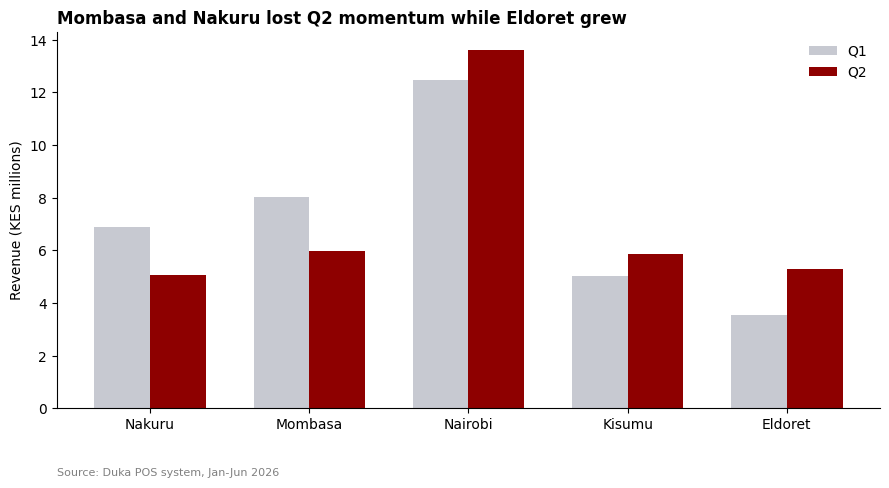

quarter,Q1,Q2,change_pct
branch,,,
Nakuru,6900200,5070200,-26.52
Mombasa,8023100,5980600,-25.46
Nairobi,12484700,13621400,9.10
Kisumu,5008900,5859200,16.98
Eldoret,3538500,5305700,49.94


In [12]:
sales["quarter"] = np.where(
    sales["order_date"].dt.month <= 3,
    "Q1",
    "Q2"
)

quarter_branch = pd.pivot_table(
    sales,
    index="branch",
    columns="quarter",
    values="revenue",
    aggfunc="sum"
)

quarter_branch["change_pct"] = (
    (quarter_branch["Q2"] / quarter_branch["Q1"] - 1) * 100
)

quarter_branch = quarter_branch.sort_values("change_pct")

fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(quarter_branch))
width = 0.35

ax.bar(
    x - width / 2,
    quarter_branch["Q1"] / 1e6,
    width,
    label="Q1",
    color="#C7C9D1"
)

ax.bar(
    x + width / 2,
    quarter_branch["Q2"] / 1e6,
    width,
    label="Q2",
    color="#8E0000"
)

ax.set_xticks(x)
ax.set_xticklabels(quarter_branch.index)

ax.set_ylabel("Revenue (KES millions)")

ax.set_title(
    "Mombasa and Nakuru lost Q2 momentum while Eldoret grew",
    loc="left",
    fontweight="bold"
)

ax.spines[["top", "right"]].set_visible(False)

ax.legend(frameon=False)

ax.text(
    0,
    -0.18,
    "Source: Duka POS system, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=8,
    color="grey"
)

plt.tight_layout()
plt.show()

quarter_branch.round(2)

In [13]:
product_before = (
    sales.groupby("product")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

In [14]:
product_before = (
    sales.groupby("product", sort=False)["revenue"]
    .sum()
)

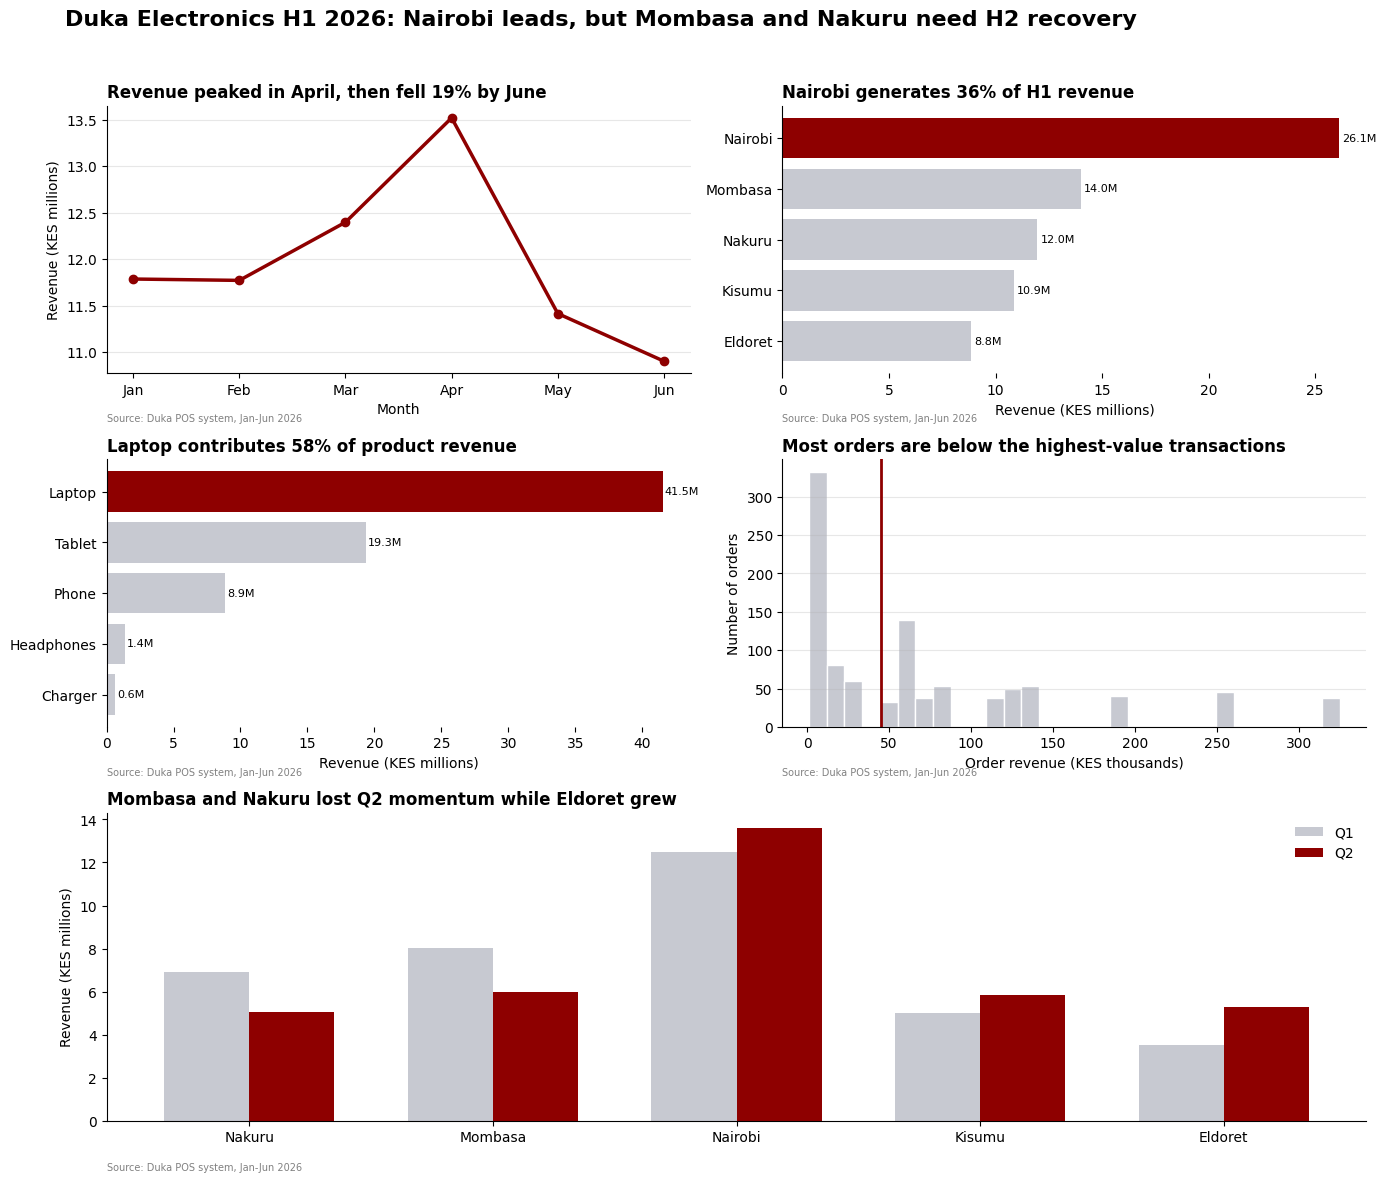

Saved correct 5-chart report to reports/duka_board_report.png


In [15]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("reports", exist_ok=True)

# Prepare summaries
monthly = (
    sales.set_index("order_date")
    .resample("MS")["revenue"]
    .sum()
)

branch_rev = (
    sales.groupby("branch")["revenue"]
    .sum()
    .sort_values()
)

product_rev = (
    sales.groupby("product")["revenue"]
    .sum()
    .sort_values()
)

order_revenue = sales["revenue"] / 1000

# Create Q1 / Q2 comparison
sales["quarter"] = np.where(
    sales["order_date"].dt.month <= 3,
    "Q1",
    "Q2"
)

quarter_branch = pd.pivot_table(
    sales,
    index="branch",
    columns="quarter",
    values="revenue",
    aggfunc="sum"
)

quarter_branch["change_pct"] = (
    (quarter_branch["Q2"] / quarter_branch["Q1"] - 1) * 100
)

quarter_branch = quarter_branch.sort_values("change_pct")

# Create one-page report
fig = plt.figure(figsize=(14, 12))

gs = fig.add_gridspec(
    3,
    2,
    height_ratios=[1, 1, 1.15]
)

fig.suptitle(
    "Duka Electronics H1 2026: Nairobi leads, but Mombasa and Nakuru need H2 recovery",
    fontsize=16,
    fontweight="bold",
    x=0.05,
    ha="left"
)

# 1. Monthly revenue trend
ax = fig.add_subplot(gs[0, 0])

labels = monthly.index.strftime("%b")

ax.plot(
    labels,
    monthly.values / 1e6,
    marker="o",
    linewidth=2.5,
    color="#8E0000"
)

drop = (monthly.iloc[-1] / monthly.max() - 1) * 100

ax.set_title(
    f"Revenue peaked in April, then fell {abs(drop):.0f}% by June",
    loc="left",
    fontweight="bold"
)

ax.set_ylabel("Revenue (KES millions)")
ax.set_xlabel("Month")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)

ax.text(
    0,
    -0.18,
    "Source: Duka POS system, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=7,
    color="grey"
)

# 2. Revenue by branch
ax = fig.add_subplot(gs[0, 1])

top_branch = branch_rev.idxmax()

colors = [
    "#8E0000" if branch == top_branch else "#C7C9D1"
    for branch in branch_rev.index
]

bars = ax.barh(
    branch_rev.index,
    branch_rev.values / 1e6,
    color=colors
)

for bar, value in zip(bars, branch_rev.values):
    ax.text(
        value / 1e6 + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{value/1e6:.1f}M",
        va="center",
        fontsize=8
    )

share = branch_rev.max() / branch_rev.sum()

ax.set_title(
    f"{top_branch} generates {share:.0%} of H1 revenue",
    loc="left",
    fontweight="bold"
)

ax.set_xlabel("Revenue (KES millions)")
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.grid(False)

ax.text(
    0,
    -0.18,
    "Source: Duka POS system, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=7,
    color="grey"
)

# 3. Revenue by product
ax = fig.add_subplot(gs[1, 0])

top_product = product_rev.idxmax()

colors = [
    "#8E0000" if product == top_product else "#C7C9D1"
    for product in product_rev.index
]

bars = ax.barh(
    product_rev.index,
    product_rev.values / 1e6,
    color=colors
)

for bar, value in zip(bars, product_rev.values):
    ax.text(
        value / 1e6 + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{value/1e6:.1f}M",
        va="center",
        fontsize=8
    )

share = product_rev.max() / product_rev.sum()

ax.set_title(
    f"{top_product} contributes {share:.0%} of product revenue",
    loc="left",
    fontweight="bold"
)

ax.set_xlabel("Revenue (KES millions)")
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.grid(False)

ax.text(
    0,
    -0.18,
    "Source: Duka POS system, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=7,
    color="grey"
)

# 4. Order revenue distribution
ax = fig.add_subplot(gs[1, 1])

ax.hist(
    order_revenue,
    bins=30,
    color="#C7C9D1",
    edgecolor="white"
)

median_value = order_revenue.median()

ax.axvline(
    median_value,
    color="#8E0000",
    linewidth=2
)

ax.set_title(
    "Most orders are below the highest-value transactions",
    loc="left",
    fontweight="bold"
)

ax.set_xlabel("Order revenue (KES thousands)")
ax.set_ylabel("Number of orders")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)

ax.text(
    0,
    -0.18,
    "Source: Duka POS system, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=7,
    color="grey"
)

# 5. Q1 vs Q2 branch performance
ax = fig.add_subplot(gs[2, :])

x = np.arange(len(quarter_branch))
width = 0.35

ax.bar(
    x - width / 2,
    quarter_branch["Q1"] / 1e6,
    width,
    label="Q1",
    color="#C7C9D1"
)

ax.bar(
    x + width / 2,
    quarter_branch["Q2"] / 1e6,
    width,
    label="Q2",
    color="#8E0000"
)

ax.set_xticks(x)
ax.set_xticklabels(quarter_branch.index)

ax.set_ylabel("Revenue (KES millions)")

ax.set_title(
    "Mombasa and Nakuru lost Q2 momentum while Eldoret grew",
    loc="left",
    fontweight="bold"
)

ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

ax.text(
    0,
    -0.16,
    "Source: Duka POS system, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=7,
    color="grey"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    "reports/duka_board_report.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved correct 5-chart report to reports/duka_board_report.png")

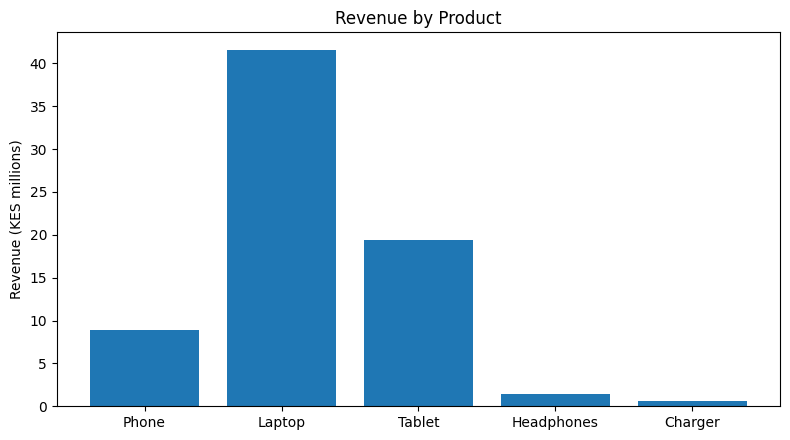

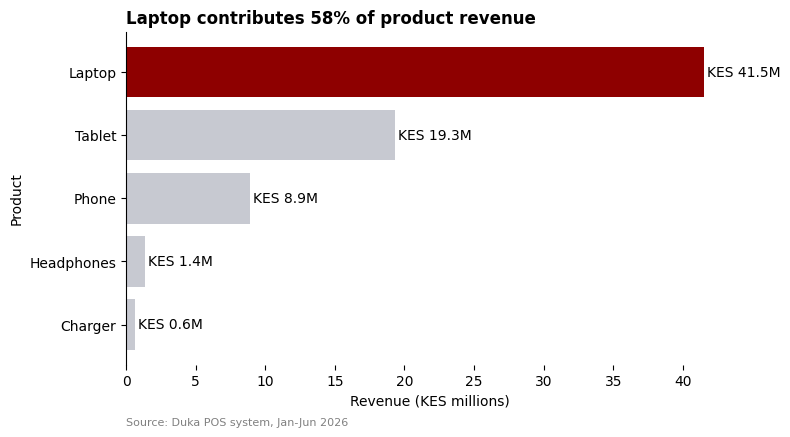

Saved figures/before.png
Saved figures/after.png


In [16]:
import os

os.makedirs("figures", exist_ok=True)

# BEFORE: simple default chart
product_before = (
    sales.groupby("product", sort=False)["revenue"]
    .sum()
)

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.bar(
    product_before.index,
    product_before.values / 1e6
)

ax.set_title("Revenue by Product")
ax.set_ylabel("Revenue (KES millions)")

plt.tight_layout()

plt.savefig(
    "figures/before.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# AFTER: redesigned chart
product_after = (
    sales.groupby("product")["revenue"]
    .sum()
    .sort_values()
)

top_product = product_after.idxmax()

colors = [
    "#8E0000" if product == top_product else "#C7C9D1"
    for product in product_after.index
]

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.barh(
    product_after.index,
    product_after.values / 1e6,
    color=colors
)

for bar, value in zip(bars, product_after.values):
    ax.text(
        value / 1e6 + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"KES {value/1e6:.1f}M",
        va="center"
    )

share = product_after.max() / product_after.sum()

ax.set_title(
    f"{top_product} contributes {share:.0%} of product revenue",
    loc="left",
    fontweight="bold"
)

ax.set_xlabel("Revenue (KES millions)")
ax.set_ylabel("Product")

ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.grid(False)

ax.text(
    0,
    -0.18,
    "Source: Duka POS system, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=8,
    color="grey"
)

plt.tight_layout()

plt.savefig(
    "figures/after.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Saved figures/before.png")
print("Saved figures/after.png")

In [17]:
%%writefile README.md
# One-Page Visual Report for the Duka Electronics Board

## Final One-Page Report

![Duka Electronics Board Report](reports/duka_board_report.png)

## Board Summary

Duka Electronics generated KES 71.8 million in H1 2026, with Nairobi contributing the largest share of revenue. Sales peaked in April before weakening in May and June, signalling softer momentum entering H2. Laptops remained the strongest product category by revenue, while tablets ranked second. Branch performance was uneven: Nairobi remained dominant, while Mombasa and Nakuru weakened in Q2 compared with Q1. Eldoret and Kisumu showed stronger momentum and should be protected while recovery actions are tested elsewhere. The board should prioritise targeted promotions and local sales interventions in Mombasa and Nakuru, while continuing to support branches that are growing. Management should also monitor monthly revenue, branch performance, product mix and channel performance through the Looker Studio dashboard. This will help the board respond quickly if H2 trends worsen, allocate marketing resources more effectively, protect profitable momentum, and identify whether recovery actions are producing measurable improvements before the end of the year.

Overwriting README.md


In [18]:
%%writefile requirements.txt
pandas
numpy
matplotlib
seaborn

Overwriting requirements.txt
